In [ ]:
# Columns to inspect by intuition
# GENHLTH, PHYSHLTH, MENTHLTH, POORHLTH, HLTHPLN1, MEDCOST, CHECKUP1, BPHIGH4, CVDINFR4, 
# CVDCRHD4, SEX, WEIGHT2, HEIGHT3, QLACTLM2, DIFFWALK, SMOKE100, SMOKDAY2, EXERANY2, 
# EXRACT11

In [2]:
import csv
import numpy as np

def read_csv_numeric(path):
    # 1) read header for the name→index mapping
    with open(path, newline='', encoding='utf-8') as f:
        reader = csv.reader(f)
        header = next(reader)
    col_idx = {name: i for i, name in enumerate(header)}

    # 2) load the rest as a 2D float array (missing -> NaN)
    # reopen so the file pointer is at the top again
    data = np.genfromtxt(
        path,
        delimiter=",",
        skip_header=1,
        dtype=float,
        missing_values=["", "NA", "NaN"],
        filling_values=np.nan
    )
    # If the CSV has only one data row, genfromtxt returns 1D; force 2D
    if data.ndim == 1:
        data = data.reshape(1, -1)

    return col_idx, data

In [6]:
x_indices, x_data = read_csv_numeric("x_train.csv")
y_indices, y_data = read_csv_numeric("y_train.csv")

In [7]:
import matplotlib.pyplot as plt

interesting_columns = ["GENHLTH", "PHYSHLTH", "MENTHLTH", "POORHLTH", "HLTHPLN1", "MEDCOST", "CHECKUP1",
                        "BPHIGH4", "SEX", "WEIGHT2", "HEIGHT3", "QLACTLM2", 
                        "DIFFWALK", "SMOKE100", "SMOKDAY2", "EXERANY2", "EXRACT11"]

single_digit = [
    'ADANXEV','ADDEPEV2','ARTHDIS2','ARTHEDU','ARTHEXER','ARTHWGT','ARTTODAY',
    'ASINHALR','ASPUNSAF','ASRCHKUP','ASTHMA3','ASTHMAGE','ASTHMED3','ASYMPTOM',
    'BLDSTOOL','BLIND','BLOODCHO','BPHIGH4','CAREGIV1','CASTHDX2','CASTHNO2',
    'CDASSIST','CDDISCUS','CDHELP','CDHOUSE','CDSOCIAL','CHCCOPD1','CHCKIDNY',
    'CHECKUP1','CHOLCHK','CIMEMLOS','CPDEMO1','CRGVEXPT','CRGVHOUS','CRGVHRS1',
    'CRGVMST2','CRGVPERS','CVDINFR4','DECIDE','DIABAGE2','DIABEDU','DIABETE3',
    'DIABEYE','DIFFALON','DIFFWALK','DRADVISE','EMTSUPRT','EXERANY2','EYEEXAM',
    'FLSHTMY2','FLUSHOT6','GENHLTH','HADHYST2','HADMAM','HADPAP2','HADSGCO1',
    'HADSIGM3','HAREHAB1','HAVARTH3','HIVTST6','HIVTSTD3','HLTHPLN1','HOWLONG',
    'HPVADSHT','HPVTEST','LANDLINE','LASTSIG3','LENGEXAM','LMTJOIN3','LSTBLDS3',
    'MEDCOST','MISTMNT','NUMHHOL2','PCPSAAD2','PCPSADE1','PCPSADI1','PCPSARE1',
    'PDIABTST','PNEUVAC3','PREDIAB1','PROFEXAM','QLACTLM2','RDUCHART','RENTHOM1',
    'SCNTLPAD','SCNTMEL1','SCNTMNY1','SCNTPAID','SEATBELT','SMOKE100','STOPSMK2',
    'STREHAB1','SXORIENT','TETANUS','TOLDHI2','TRNSGNDR','USEEQUIP','USENOW3',
    'VETERAN3','VIEYEXM2','VIPRFVS2','WTCHSALT',
    '_CHOLCHK','_HCVU651','_LLCPWT','_LMTSCL1','_MICHD','_PNEUMO2','_RACEG21',
    '_RFBMI5','_RFCHOL','_RFDRHV5','_RFHYPE5','_SMOKER3','_TOTINDA', 'SEX', 'SMOKDAY2'
]

# 77 / 99
double_digit = [
    'ADDOWN','ADEAT1','ADENERGY','ADFAIL','ADMOVE','ADPLEASR','ADSLEEP','ADTHINK',
    'ARTHSOCL','AVEDRNK2','CHKHEMO3','CRGVPRB1','CRGVREL1','DOCTDIAB','EXRACT11',
    'EXRACT21','FEETCHK','HHADULT','HPVADVC2','IMFVPLAC','INCOME2','JOINPAIN',
    'LASTSMK2','MENTHLTH','PERSDOC2','PHYSHLTH','POORHLTH','PSATIME','VINOCRE2',
    'WHRTST10','_ASTHMS1','_CRACE1','_DRDXAR1','_PRACE1','_RACE','_RACE_G1',
    '_WT2RAKE'
]

# 777 / 999
triple_digit = [
    'ALCDAY5','ASACTLIM','BLDSUGAR','DRNK3GE5','DRNKANY5',
    'EXERHMM1','EXERHMM2','EXEROFT1','EXEROFT2','FEETCHK2',
    'FRUIT1','FRUITJU1','FVBEANS','FVGREEN','FVORANG',
    'LONGWTCH','MAXDRNKS','STRENGTH','VEGETAB1','_BMI5','_RFBING5'
]

# 7777 / 9999
four_digit = [
    'HEIGHT3','WEIGHT2','WTKG3'
]

for c in interesting_columns:
    if c in single_digit:
        x_data[x_data[:, x_indices[c]] == 7, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 8, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 9, x_indices[c]] = np.nan
    elif c in double_digit:
        x_data[x_data[:, x_indices[c]] == 77, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 88, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 99, x_indices[c]] = np.nan
    elif c in triple_digit:
        x_data[x_data[:, x_indices[c]] == 777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 999, x_indices[c]] = np.nan
    elif c in four_digit:
        x_data[x_data[:, x_indices[c]] == 7777, x_indices[c]] = np.nan
        x_data[x_data[:, x_indices[c]] == 8888, x_indices[c]] = 0
        x_data[x_data[:, x_indices[c]] == 9999, x_indices[c]] = np.nan
    else: 
        raise Exception("Not in any group", c)
    
x_data[x_data[:, x_indices["WEIGHT2"]] <= 1000, x_indices["WEIGHT2"]] = x_data[x_data[:, x_indices["WEIGHT2"]] <= 1000, x_indices["WEIGHT2"]] * 0.453592
x_data[x_data[:, x_indices["WEIGHT2"]] >= 9000, x_indices["WEIGHT2"]] = x_data[x_data[:, x_indices["WEIGHT2"]] >= 9000, x_indices["WEIGHT2"]] - 9000
x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]] = ((x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]]) // 100) * 30.48 + ((x_data[x_data[:, x_indices["HEIGHT3"]] <= 1000, x_indices["HEIGHT3"]]) % 100) * 2.54
x_data[x_data[:, x_indices["HEIGHT3"]] >= 9000, x_indices["HEIGHT3"]] = x_data[x_data[:, x_indices["HEIGHT3"]] >= 9000, x_indices["HEIGHT3"]] - 9000
x_data[x_data[:, x_indices["WEIGHT2"]] > 200, x_indices["WEIGHT2"]] = np.nan


In [8]:
nans = np.isnan(x_data).sum(axis=0)
cols_with_nans = []

for index, nas in enumerate(nans):
    if nas > 150000:
        for k, v in x_indices.items():
            if v == index:
                print("Column " + str(k) + " has " + str(nas) + " NAs")
                cols_with_nans.append(k)
                break

print((set(interesting_columns) & set(cols_with_nans)))

Column COLGHOUS has 328103 NAs
Column LADULT has 328103 NAs
Column CTELNUM1 has 188720 NAs
Column CELLFON2 has 188720 NAs
Column CADULT has 188721 NAs
Column PVTRESD2 has 188720 NAs
Column CCLGHOUS has 327334 NAs
Column CSTATE has 188719 NAs
Column LANDLINE has 189287 NAs
Column HHADULT has 192544 NAs
Column POORHLTH has 163417 NAs
Column BPMEDS has 196334 NAs
Column ASTHNOW has 284153 NAs
Column DIABAGE2 has 285915 NAs
Column NUMPHON2 has 318245 NAs
Column PREGNANT has 279663 NAs
Column SMOKDAY2 has 191623 NAs
Column STOPSMK2 has 282510 NAs
Column LASTSMK2 has 237369 NAs
Column AVEDRNK2 has 170906 NAs
Column DRNK3GE5 has 171212 NAs
Column MAXDRNKS has 171522 NAs
Column EXEROFT2 has 181261 NAs
Column EXERHMM2 has 181400 NAs
Column LMTJOIN3 has 226907 NAs
Column ARTHDIS2 has 227043 NAs
Column ARTHSOCL has 227197 NAs
Column JOINPAIN has 229088 NAs
Column FLSHTMY2 has 186763 NAs
Column IMFVPLAC has 186001 NAs
Column HIVTSTD3 has 243418 NAs
Column WHRTST10 has 243561 NAs
Column PDIABTST ha

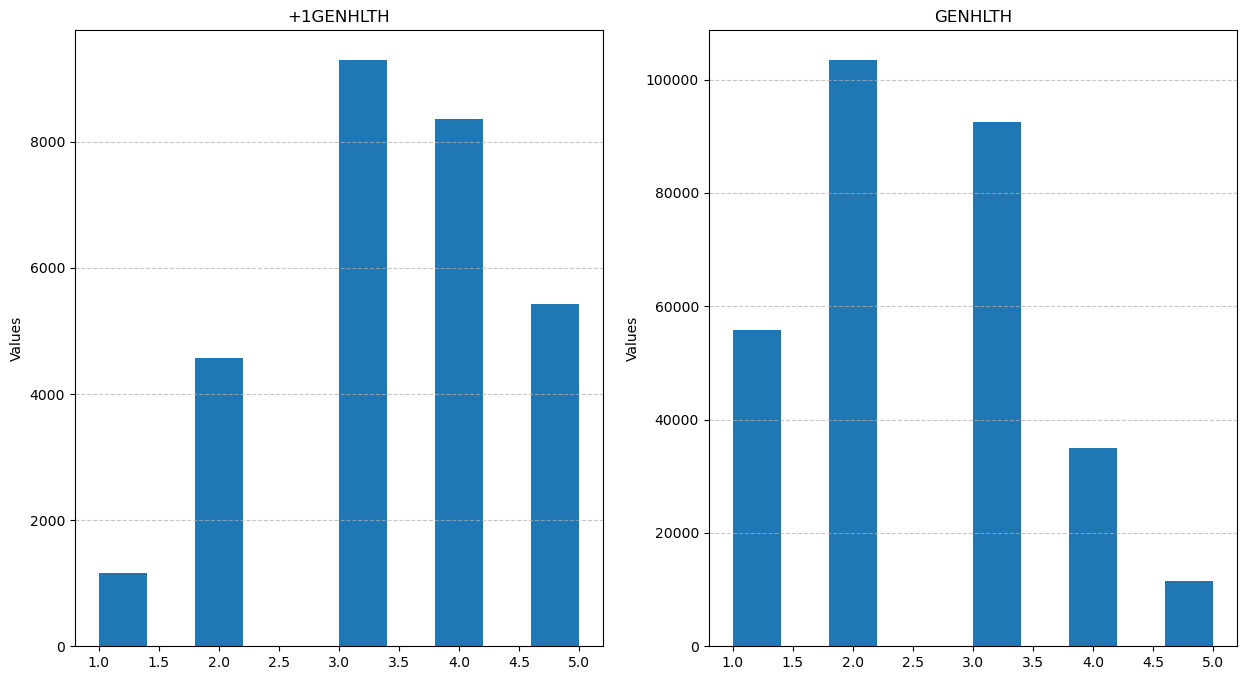

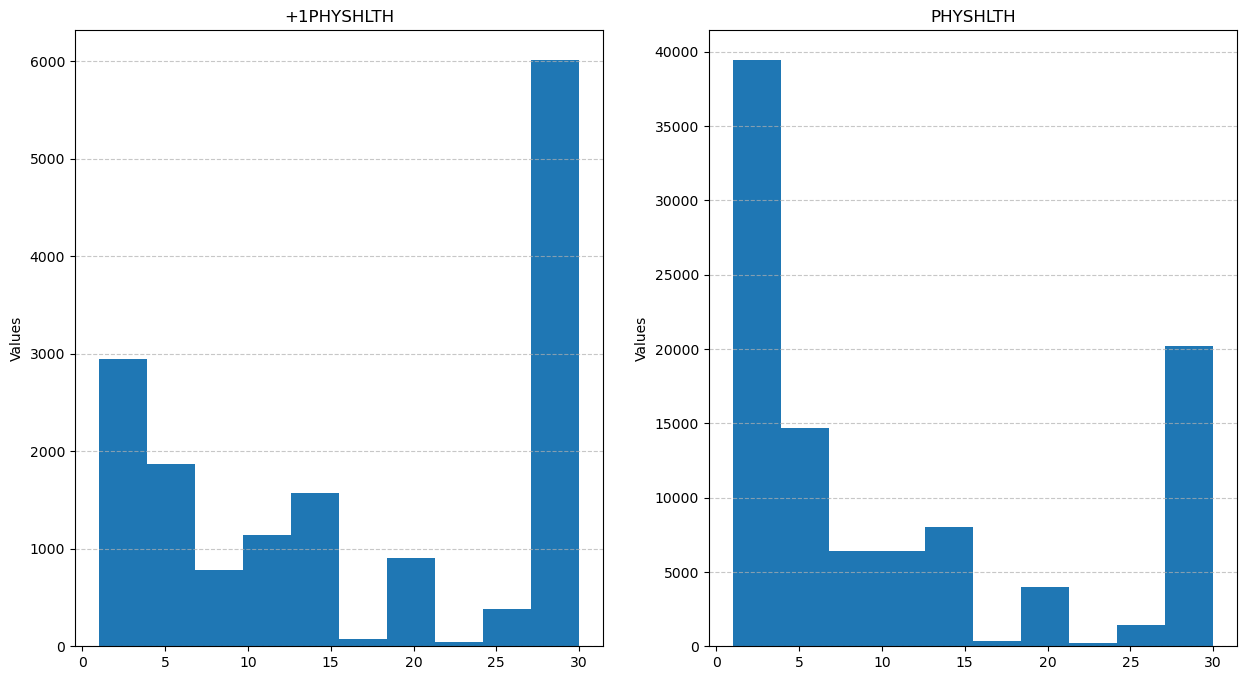

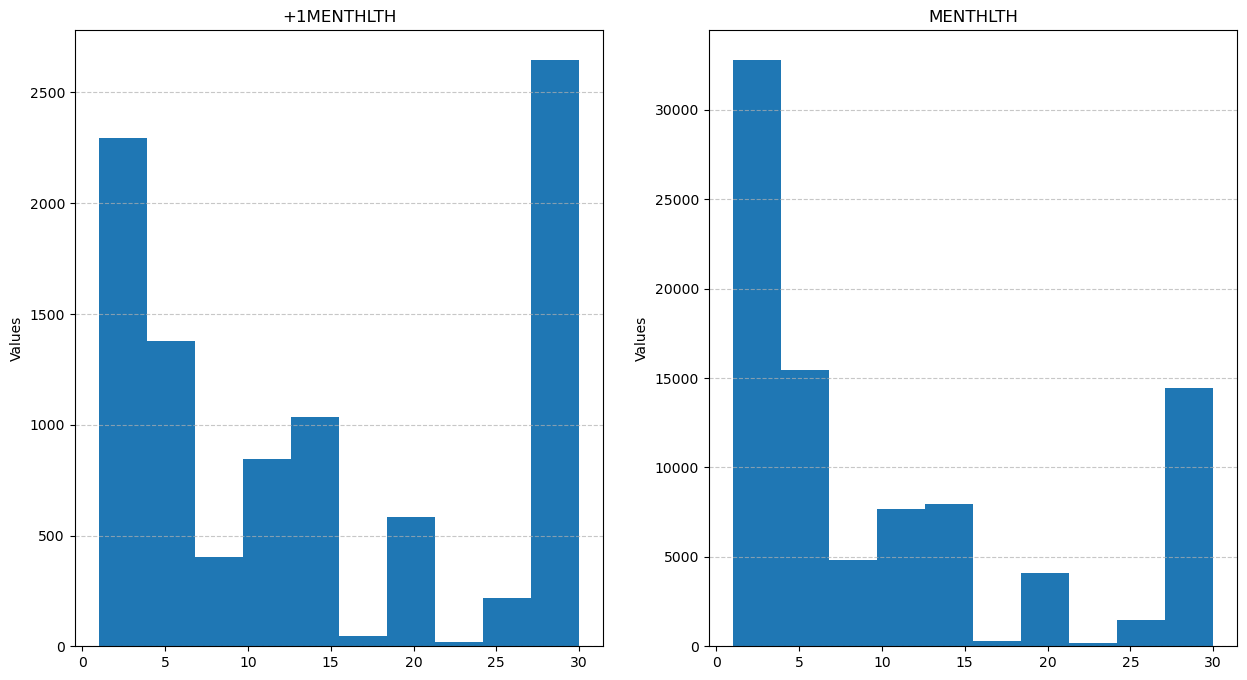

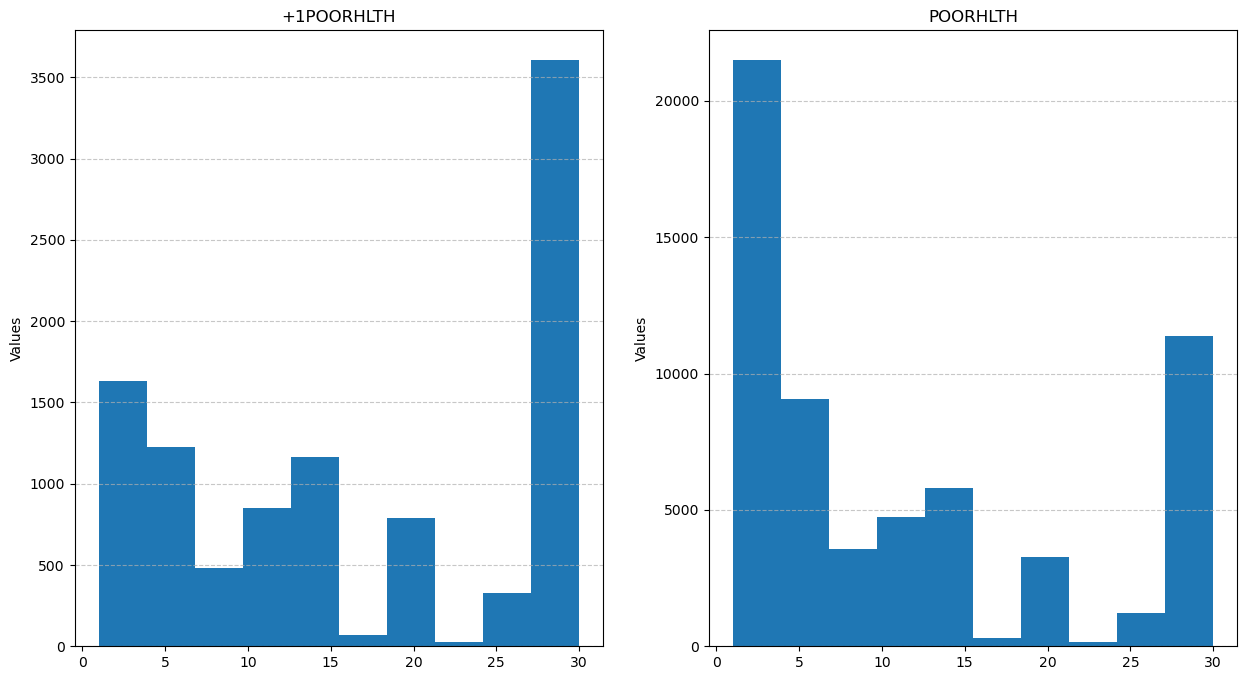

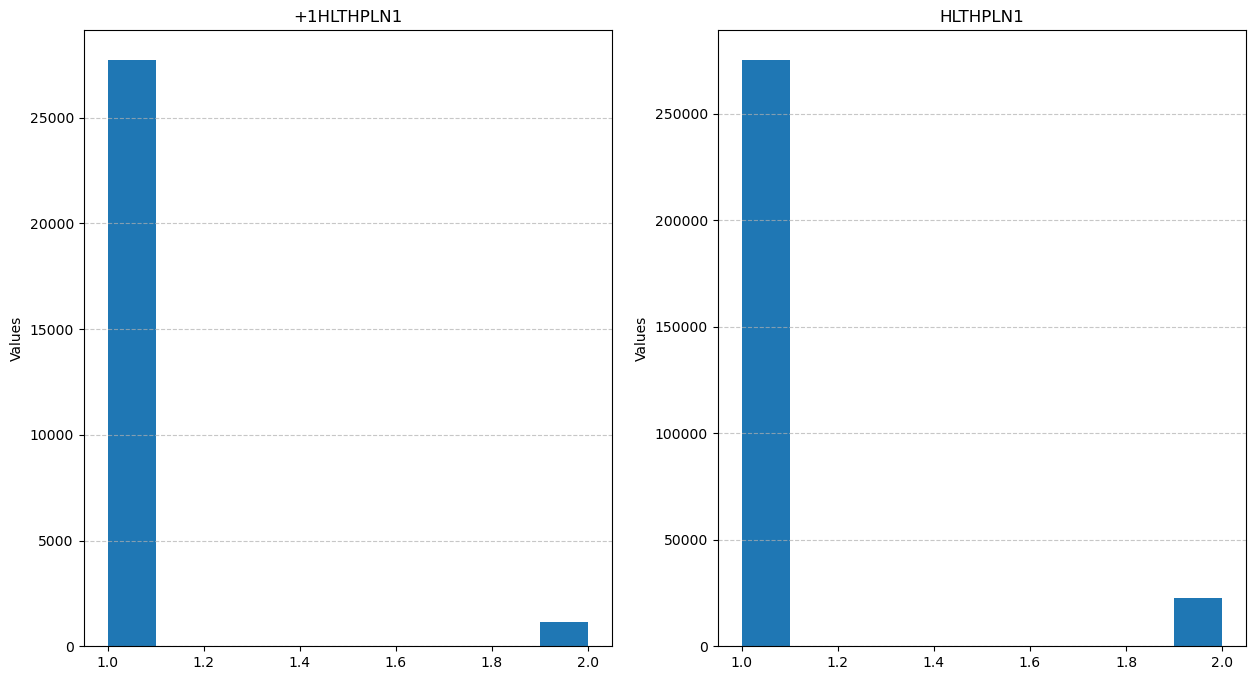

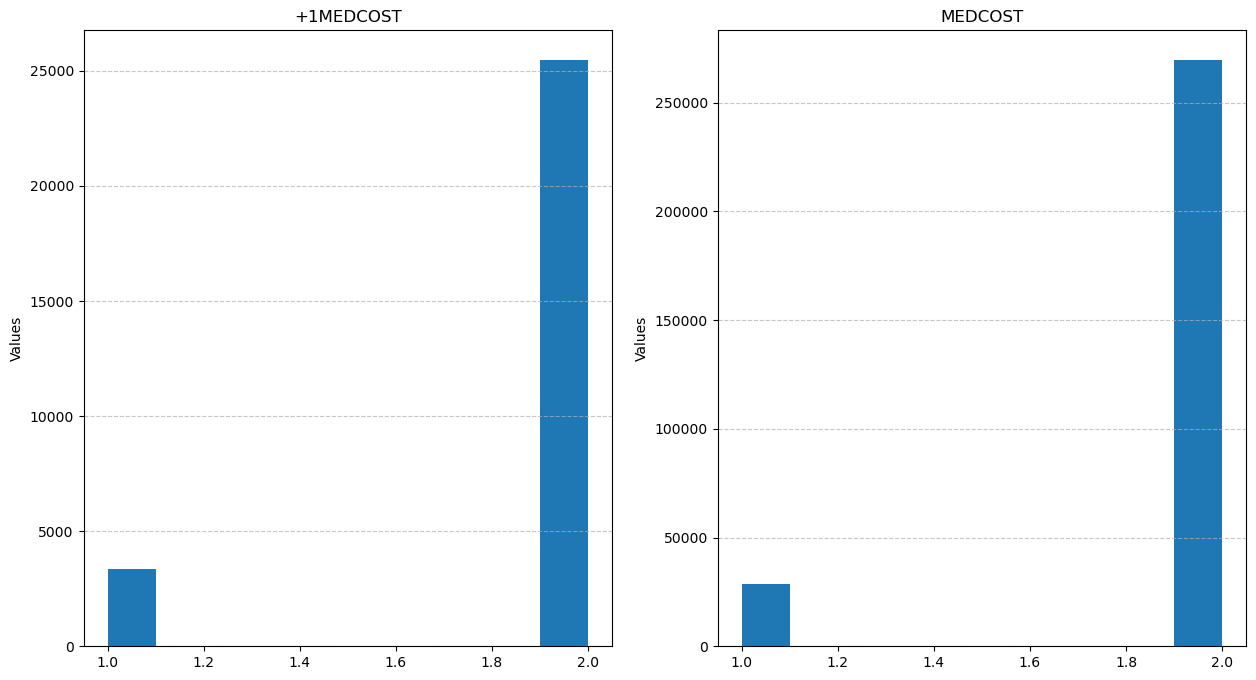

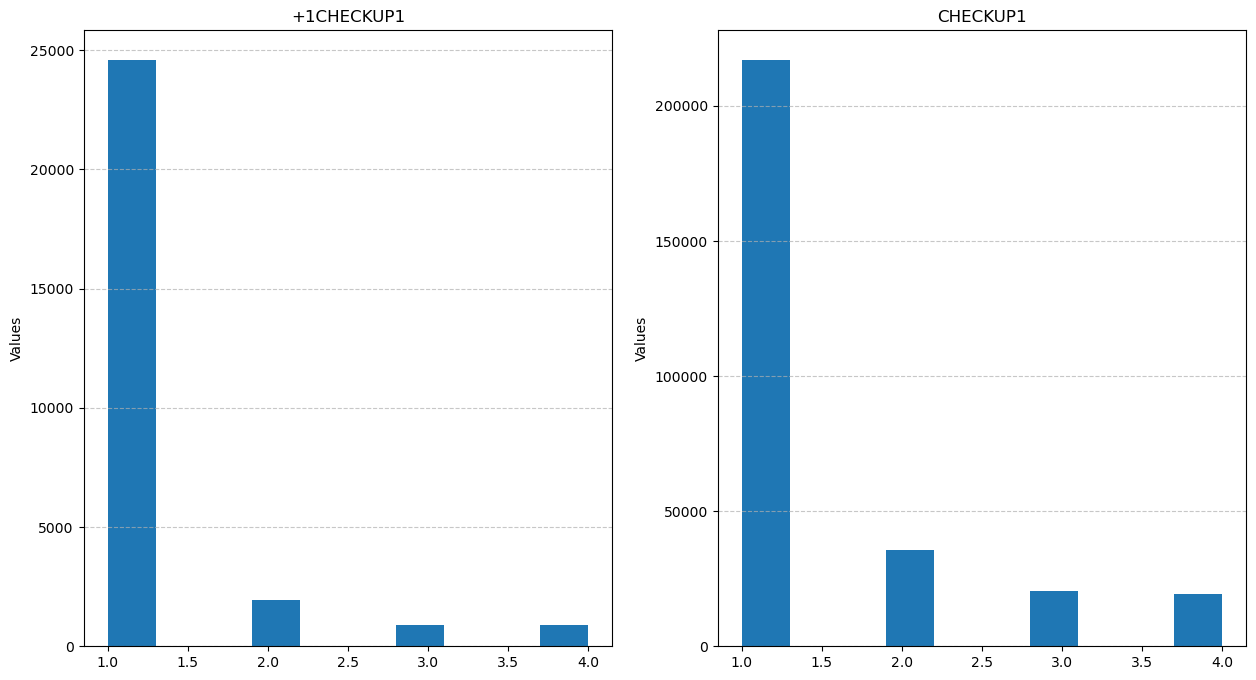

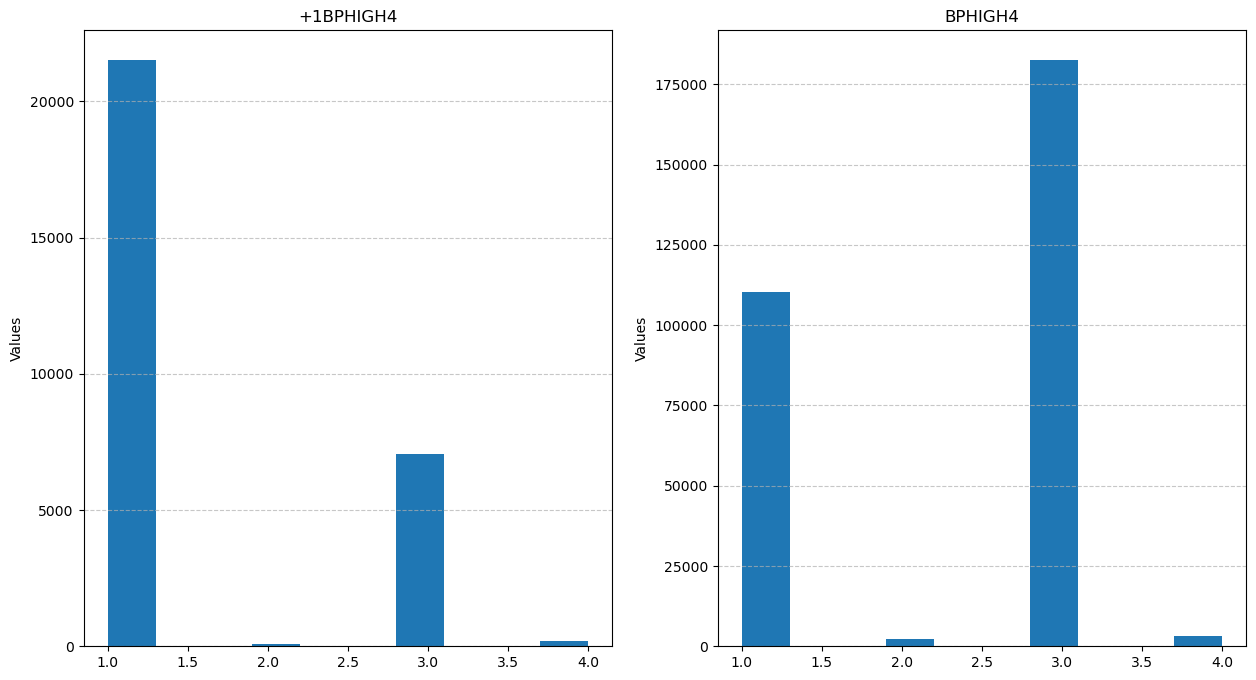

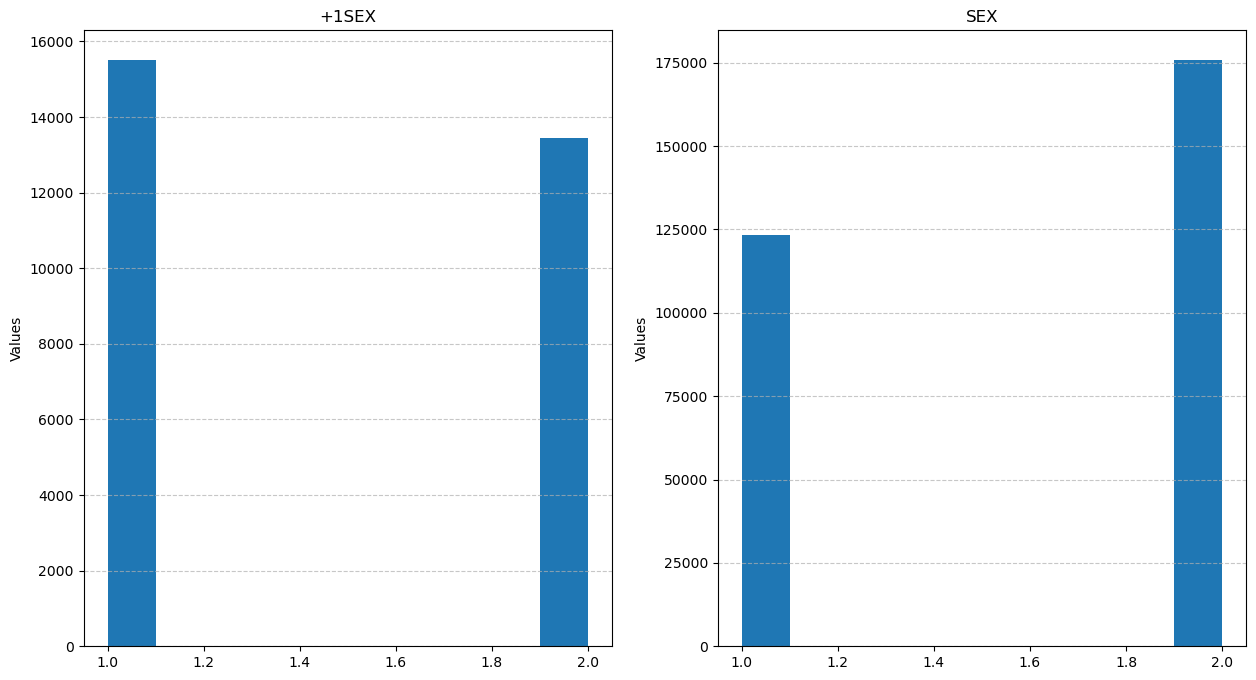

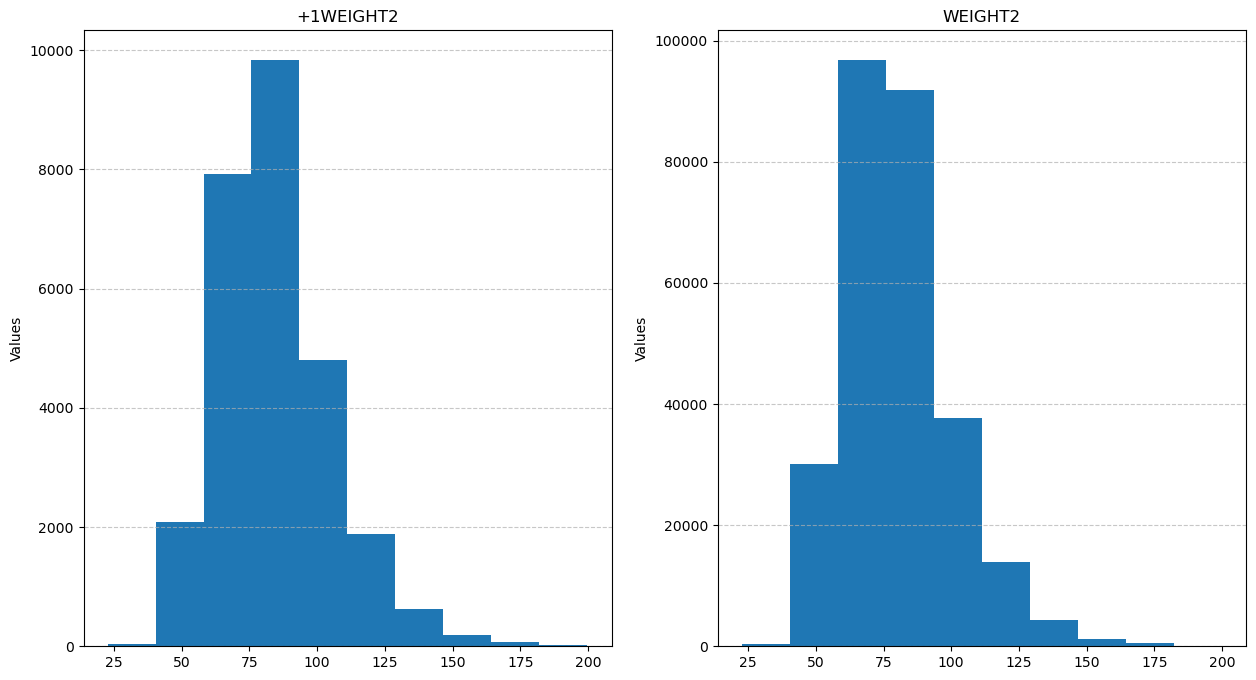

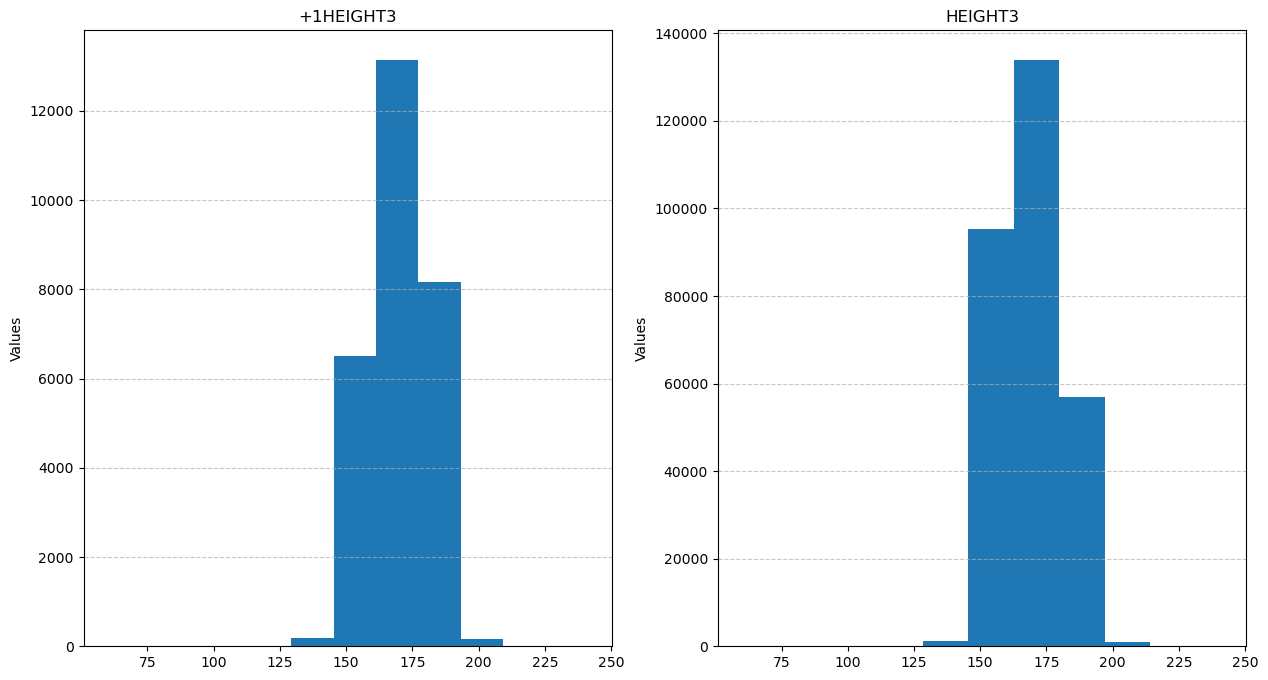

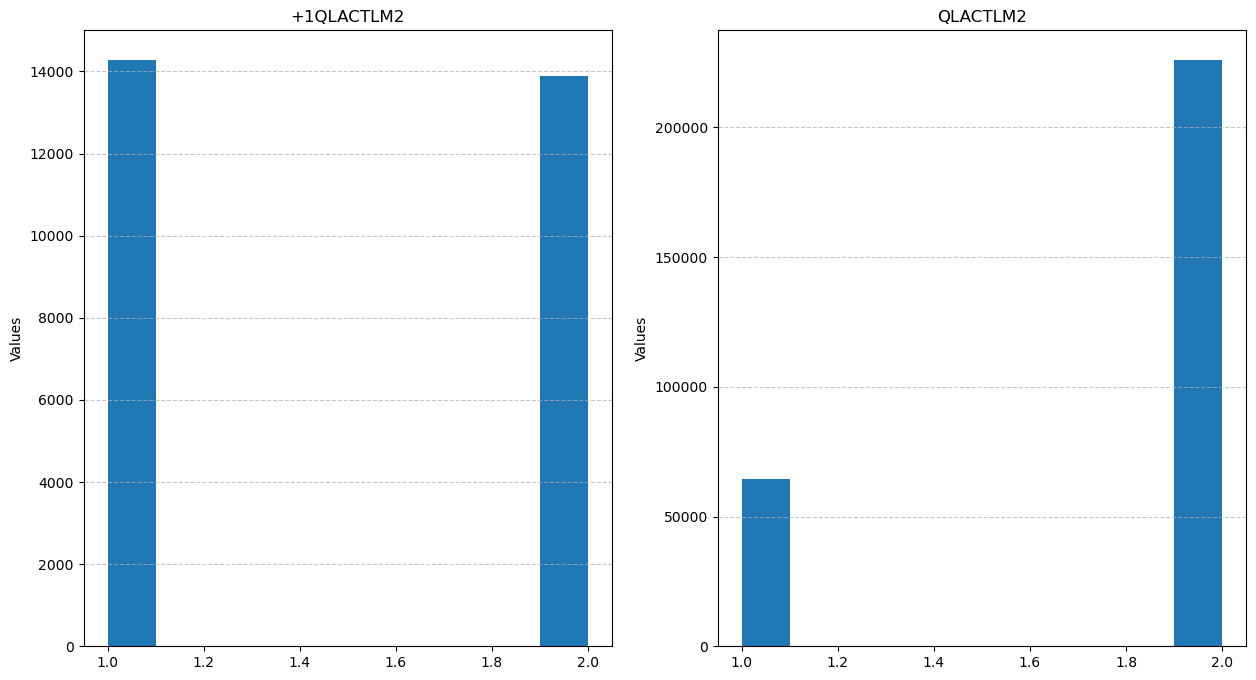

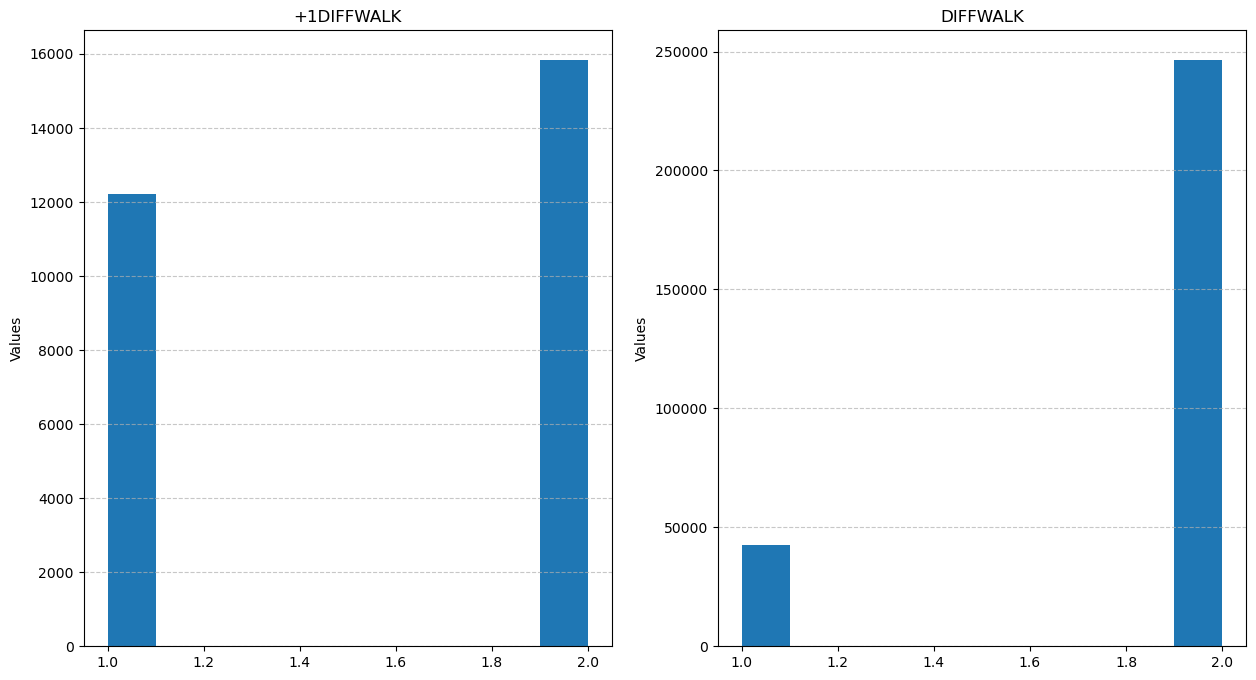

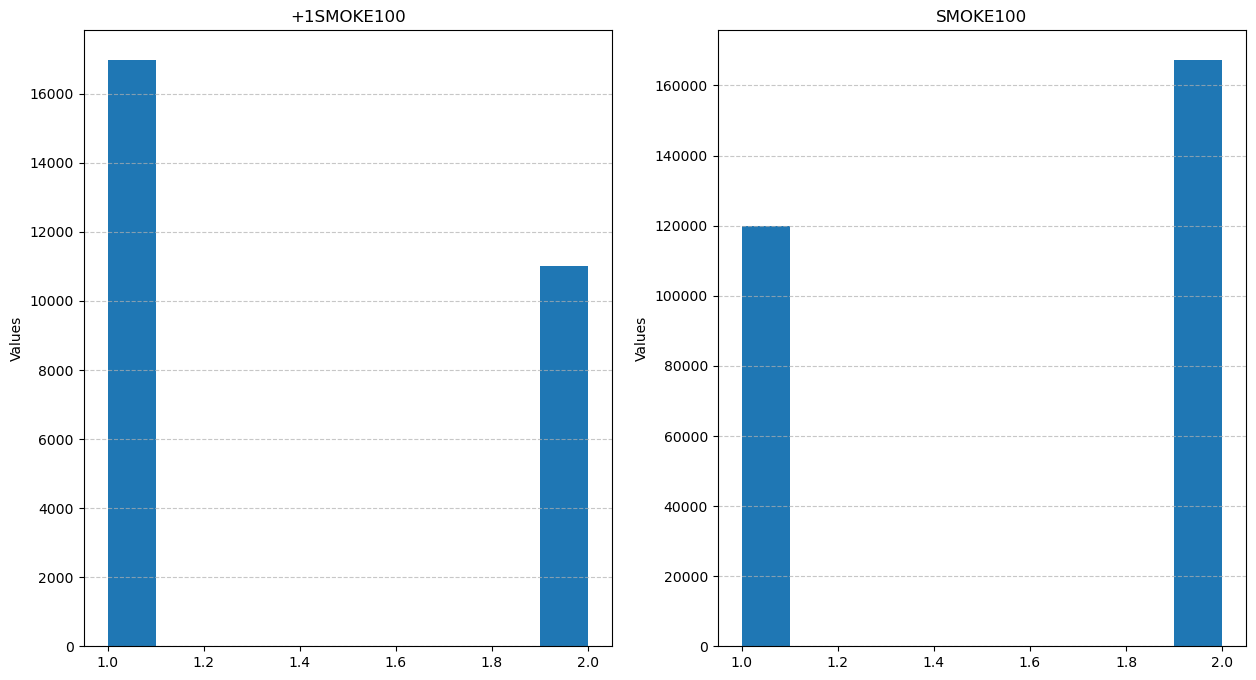

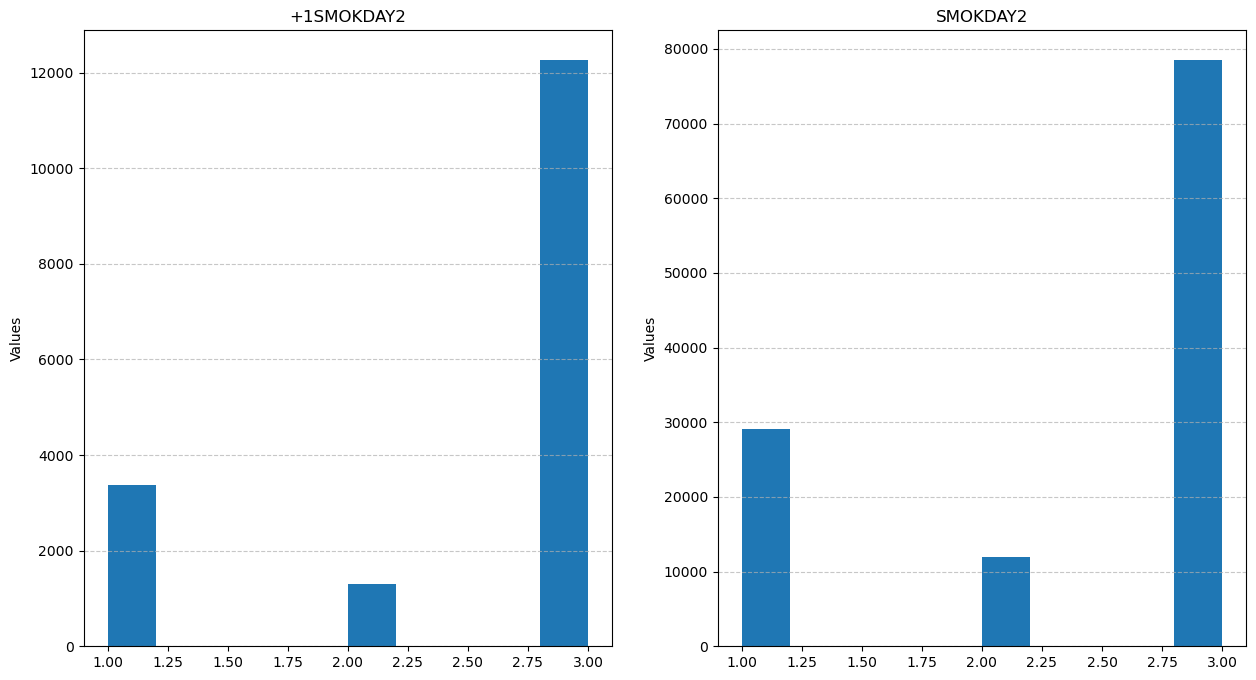

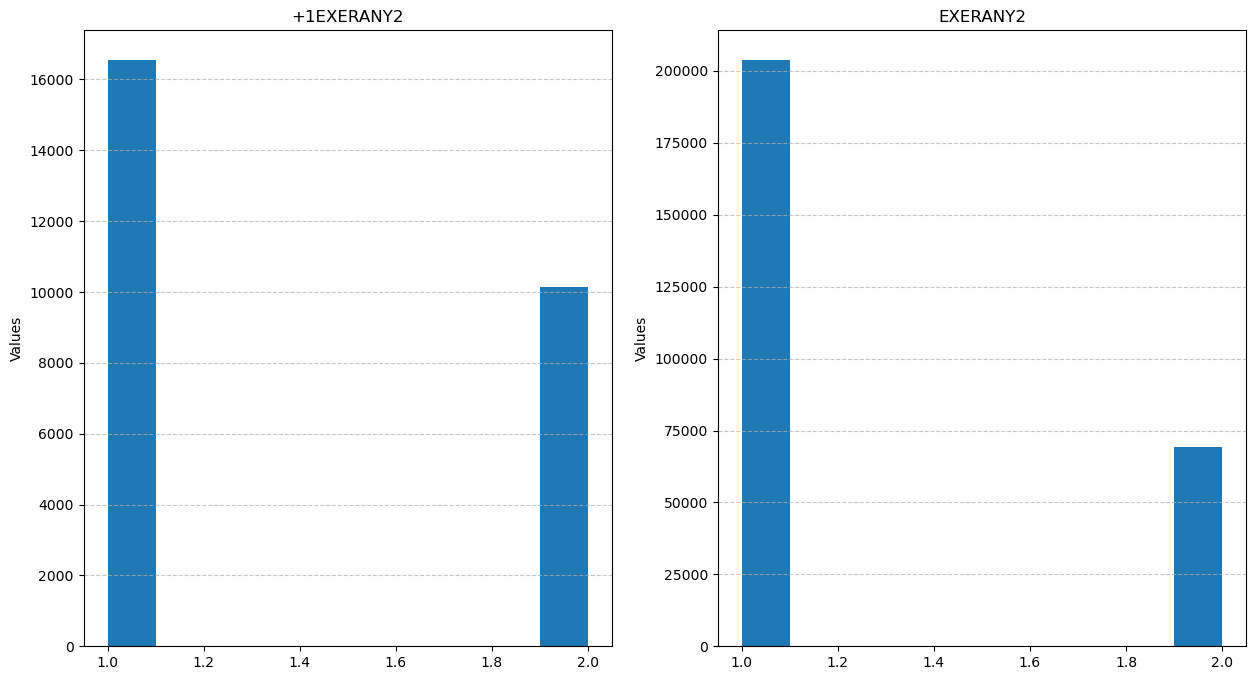

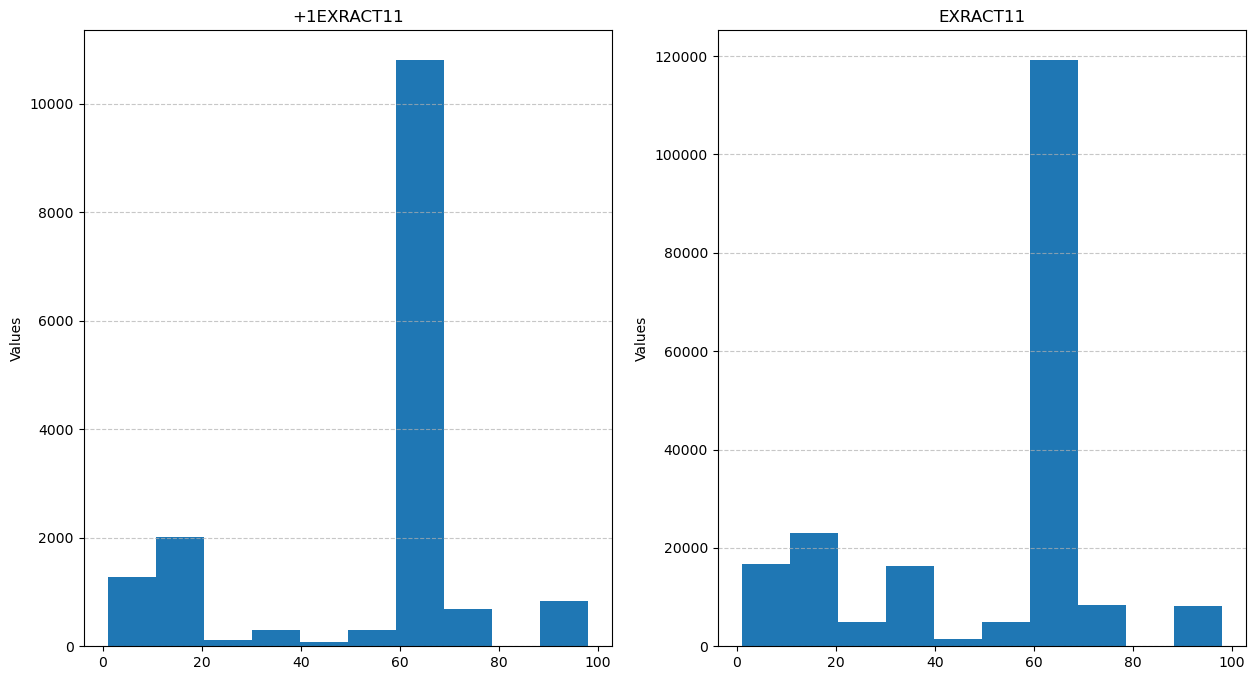

In [ ]:
for c in interesting_columns:
    m = y_data[:, 1] == 1
    m2 = y_data[:, 1] == -1

    fig, axes = plt.subplots(1, 2, sharex="all", sharey="none", figsize=(15, 8))
    axes.flatten()[0].hist(x_data[m, x_indices[c]], bins=10)
    axes[0].set_title("+1" + str(c))
    axes.flatten()[0].set_ylabel("Values")
    axes.flatten()[0].grid(axis='y', linestyle='--', alpha=0.7)
    axes.flatten()[1].hist(x_data[m2, x_indices[c]])
    axes[1].set_title("-1" + str(c))
    axes.flatten()[1].set_ylabel("Values")
    axes.flatten()[1].grid(axis='y', linestyle='--', alpha=0.7)
    # plt.boxplot([x_data[m, x_indices[c]], x_data[m2, x_indices[c]]], labels=["1", "-1"])

    plt.title(c)
    plt.ylabel("Values")
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.show()

In [1]:
nans = np.isnan(x_data).sum(axis=0)
cols_with_nans = []

for index, nas in enumerate(nans):
    if nas > 150000:
        for k, v in x_indices.items():
            if v == index:
                print("Column " + str(k) + " has " + str(nas) + " NAs")
                cols_with_nans.append(k)
                break

print((set(interesting_columns) & set(cols_with_nans)))

NameError: name 'np' is not defined